# EMQA_L3_returns_ro

**Romanian daily base day-ahead price and its daily log change r_t = 100 ln(P_t/P_t-1), 2019-01-01 to 2026-10-31 (CET delivery days), with the energy crisis (Sep 2021 to Dec 2022) shaded: calm and turbulent stretches alternate (volatility clustering).**

Energy Markets Quantitative Analysis (EMQA), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L3/EMQA_L3_returns_ro/EMQA_L3_returns_ro.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
C_PCT, C_EUR = PAL['RO'], PAL['c7']          # percent changes, EUR/MWh changes


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    # legend centred under the axes, outside the plotting area
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def slide(label, key, x, k=None):
    # prints a number shown on the slide; [key] = its name in lectures/L3/L3_numbers.json
    if k is not None:
        x = round(float(x), k)
    print(f'{label:<58s} {x}   [{key}]')

## Daily price and daily change

The daily change in percent is $r_t = 100\ln(P_t/P_{t-1})$, on the full calendar (every day has an auction). Large changes come in clusters.

In [3]:
# Romanian daily base price (mean of all MTUs of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month; panel from 2019-01-01, on the full calendar
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD['RO'].reindex(CAL)
print('Romania, daily base price:', START.date(), 'to', END.date(), '|', len(CAL), 'days, missing:', int(P.isna().sum()))

Romania, daily base price: 2019-01-01 to 2026-10-31 | 2861 days, missing: 0


In [4]:
# daily changes on the full calendar: percent (log) and EUR/MWh
r = 100 * np.log(P.where(P > 0)).diff()      # r_t = 100 ln(P_t / P_{t-1}); missing if a price is <= 0
u = P.diff()                                  # Delta P_t = P_t - P_{t-1}, EUR/MWh

### Numbers on the slide

In [5]:
rr = r.dropna()
slide('daily changes', 'ret.n', int(len(rr)))
slide('largest rise, %', 'ret.max', rr.max(), 1)
slide('  on', 'ret.max_date', str(rr.idxmax().date()))
slide('largest fall, %', 'ret.min', rr.min(), 1)
slide('  on', 'ret.min_date', str(rr.idxmin().date()))
slide('days with |r_t| > 50%', 'ret.n_abs50', int((rr.abs() > 50).sum()))

daily changes                                              2860   [ret.n]
largest rise, %                                            194.4   [ret.max]
  on                                                       2023-01-02   [ret.max_date]
largest fall, %                                            -226.9   [ret.min]
  on                                                       2023-12-25   [ret.min_date]
days with |r_t| > 50%                                      189   [ret.n_abs50]


### Chart

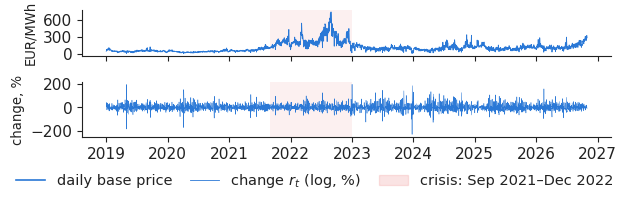

In [6]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
MON = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


def yfmt(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


def mfmt(ax, step=1):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=step))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: MON[mdates.num2date(v).month - 1] +
                                               (f'\n{mdates.num2date(v).year}' if mdates.num2date(v).month == 1 or p == 0 else '')))
from matplotlib.patches import Patch
CRISIS = (pd.Timestamp('2021-09-01'), pd.Timestamp('2022-12-31'))   # energy crisis, shaded

from matplotlib.ticker import MaxNLocator
fig, axs = plt.subplots(2, 1, figsize=(6.4, 2.1), sharex=True, gridspec_kw={'height_ratios': [1, 1.2]})
axs[0].plot(P.index, P.values, color=PAL['RO'], lw=0.6)
axs[0].set_ylabel('EUR/MWh', fontsize=9.5)
axs[1].plot(rr.index, rr.values, color=C_PCT, lw=0.35)
axs[1].set_ylabel('change, %', fontsize=9.5)
for ax in axs:
    ax.axvspan(*CRISIS, color=PAL['c8'], alpha=0.08, lw=0)
yfmt(axs[1])
legend_bottom(fig, handles=[plt.Line2D([], [], color=PAL['RO'], lw=1.2), plt.Line2D([], [], color=C_PCT, lw=0.6),
                            Patch(color=PAL['c8'], alpha=0.15)],
              labels=['daily base price', 'change $r_t$ (log, %)', 'crisis: Sep 2021–Dec 2022'], ncol=3)
for ax in axs:
    ax.yaxis.set_major_locator(MaxNLocator(3))
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.savefig('returns_ro.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()